# Offline EDA (without SageMaker)

X/ input/independent variables:

<br>Ambient temperature (AT) C â€“6.23 37.10 17.71
<br>Turbine inlet temperature (TIT) C 1000.85 1100.89 1081.43
<br>Turbine after temperature (TAT) C 511.04 550.61 546.16


<br>Air filter difference pressure (AFDP) mbar 2.09 7.61 3.93
<br>Gas turbine exhaust pressure (GTEP) mbar 17.70 40.72 25.56
<br>Ambient pressure (AP) mbar 985.85 1036.56 1013.07

<br>Ambient humidity (AH) (%) 24.08 100.20 77.87
<br>Compressor discharge pressure (CDP) mbar 9.85 15.16 12.06



<br> Possible predictors (x variable):
<br>CO - Carbon Monoxide flue gas emissions -  Optional; emission level may correlate with plant performance
<br>NOX - Nitrous Oxide flue gas emissions -  Optional; emission level may correlate with combustion efficiency
<br>Carbon monoxide (CO) mg/m3 0.00 44.10 2.37
<br>Nitrogen oxides (NOx) mg/m3 25.90 119.91 65.29

<br>Y/output/dependent variables:
<br>TEY - Total energy yield (kW) — analogous to PE in UCI dataset
Turbine energy yield (TEY) MWH 100.02 179.50 133.51

In [1]:
import pandas as pd

# Load datasets from local "Data" subfolder
turkish_holidays = pd.read_csv("Data/TurkishHolidays.tsv", sep='\t', encoding='latin1') # Specify tsv encoding
weather_data = pd.read_csv("Data/CCPP 2011-2015 Full Weather Data.csv")
gt_2011 = pd.read_csv("Data/gt_2011_wDate.csv")
gt_2012 = pd.read_csv("Data/gt_2012_wDate.csv")
gt_2013 = pd.read_csv("Data/gt_2013_wDate.csv")
gt_2014 = pd.read_csv("Data/gt_2014_wDate.csv")
gt_2015 = pd.read_csv("Data/gt_2015_wDate.csv")

# Inspect and merge the 7 data files

In [2]:
weather_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              43824 non-null  object 
 1   datetime          43824 non-null  object 
 2   temp              43824 non-null  float64
 3   feelslike         43824 non-null  float64
 4   dew               43824 non-null  float64
 5   humidity          43824 non-null  float64
 6   precip            43824 non-null  float64
 7   precipprob        43824 non-null  int64  
 8   preciptype        1509 non-null   object 
 9   snow              43824 non-null  float64
 10  snowdepth         43824 non-null  float64
 11  windgust          24789 non-null  float64
 12  windspeed         43824 non-null  float64
 13  winddir           43824 non-null  float64
 14  sealevelpressure  43824 non-null  float64
 15  cloudcover        43816 non-null  float64
 16  visibility        43147 non-null  float6

In [3]:
gt_2011.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7411 entries, 0 to 7410
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   DT      7411 non-null   object 
 1   AT      7411 non-null   float64
 2   AP      7411 non-null   float64
 3   AH      7411 non-null   float64
 4   AFDP    7411 non-null   float64
 5   GTEP    7411 non-null   float64
 6   TIT     7411 non-null   float64
 7   TAT     7411 non-null   float64
 8   TEY     7411 non-null   float64
 9   CDP     7411 non-null   float64
 10  CO      7411 non-null   float64
 11  NOX     7411 non-null   float64
dtypes: float64(11), object(1)
memory usage: 694.9+ KB


In [4]:
gt_2012.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7628 entries, 0 to 7627
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   DT      7628 non-null   object 
 1   AT      7628 non-null   float64
 2   AP      7628 non-null   float64
 3   AH      7628 non-null   float64
 4   AFDP    7628 non-null   float64
 5   GTEP    7628 non-null   float64
 6   TIT     7628 non-null   float64
 7   TAT     7628 non-null   float64
 8   TEY     7628 non-null   float64
 9   CDP     7628 non-null   float64
 10  CO      7628 non-null   float64
 11  NOX     7628 non-null   float64
dtypes: float64(11), object(1)
memory usage: 715.3+ KB


In [5]:
gt_2013.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7152 entries, 0 to 7151
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   DT      7152 non-null   object 
 1   AT      7152 non-null   float64
 2   AP      7152 non-null   float64
 3   AH      7152 non-null   float64
 4   AFDP    7152 non-null   float64
 5   GTEP    7152 non-null   float64
 6   TIT     7152 non-null   float64
 7   TAT     7152 non-null   float64
 8   TEY     7152 non-null   float64
 9   CDP     7152 non-null   float64
 10  CO      7152 non-null   float64
 11  NOX     7152 non-null   float64
dtypes: float64(11), object(1)
memory usage: 670.6+ KB


In [6]:
gt_2013.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7152 entries, 0 to 7151
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   DT      7152 non-null   object 
 1   AT      7152 non-null   float64
 2   AP      7152 non-null   float64
 3   AH      7152 non-null   float64
 4   AFDP    7152 non-null   float64
 5   GTEP    7152 non-null   float64
 6   TIT     7152 non-null   float64
 7   TAT     7152 non-null   float64
 8   TEY     7152 non-null   float64
 9   CDP     7152 non-null   float64
 10  CO      7152 non-null   float64
 11  NOX     7152 non-null   float64
dtypes: float64(11), object(1)
memory usage: 670.6+ KB


In [7]:
gt_2014.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7158 entries, 0 to 7157
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   DT      7158 non-null   object 
 1   AT      7158 non-null   float64
 2   AP      7158 non-null   float64
 3   AH      7158 non-null   float64
 4   AFDP    7158 non-null   float64
 5   GTEP    7158 non-null   float64
 6   TIT     7158 non-null   float64
 7   TAT     7158 non-null   float64
 8   TEY     7158 non-null   float64
 9   CDP     7158 non-null   float64
 10  CO      7158 non-null   float64
 11  NOX     7158 non-null   float64
dtypes: float64(11), object(1)
memory usage: 671.2+ KB


In [8]:
gt_2015.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7384 entries, 0 to 7383
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   DT      7384 non-null   object 
 1   AT      7384 non-null   float64
 2   AP      7384 non-null   float64
 3   AH      7384 non-null   float64
 4   AFDP    7384 non-null   float64
 5   GTEP    7384 non-null   float64
 6   TIT     7384 non-null   float64
 7   TAT     7384 non-null   float64
 8   TEY     7384 non-null   float64
 9   CDP     7384 non-null   float64
 10  CO      7384 non-null   float64
 11  NOX     7384 non-null   float64
dtypes: float64(11), object(1)
memory usage: 692.4+ KB


# Combine all CCPP datasets by year

In [9]:
# Merge gt_2011 to gt_2015 in order
gt_all_years = pd.concat([gt_2011, gt_2012, gt_2013, gt_2014, gt_2015], ignore_index=True)

In [10]:
gt_all_years.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36733 entries, 0 to 36732
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   DT      36733 non-null  object 
 1   AT      36733 non-null  float64
 2   AP      36733 non-null  float64
 3   AH      36733 non-null  float64
 4   AFDP    36733 non-null  float64
 5   GTEP    36733 non-null  float64
 6   TIT     36733 non-null  float64
 7   TAT     36733 non-null  float64
 8   TEY     36733 non-null  float64
 9   CDP     36733 non-null  float64
 10  CO      36733 non-null  float64
 11  NOX     36733 non-null  float64
dtypes: float64(11), object(1)
memory usage: 3.4+ MB


In [11]:
gt_all_years.head()

,DT,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX
0,2011-01-01T00:00:00,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952
1,2011-01-01T01:00:00,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377
2,2011-01-01T02:00:00,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776
3,2011-01-01T03:00:00,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505
4,2011-01-01T04:00:00,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028


In [12]:
weather_data.head()

,name,datetime,temp,feelslike,dew,humidity,precip,precipprob,preciptype,snow,...,sealevelpressure,cloudcover,visibility,solarradiation,solarenergy,uvindex,severerisk,conditions,icon,stations
0,"Marmara Ereglisi, Turkey",2011-01-01T00:00:00,-2.3,-2.3,-4.7,83.98,0.0,0,NaN,0.0,...,1022.2,0.0,12.0,NaN,NaN,NaN,NaN,Clear,clear-night,"17056099999,LTBU,17054099999,17115099999,17060..."
1,"Marmara Ereglisi, Turkey",2011-01-01T01:00:00,-1.6,-1.6,-4.7,79.28,0.0,0,NaN,0.0,...,1021.4,0.0,12.0,NaN,NaN,NaN,NaN,Clear,clear-night,"17056099999,LTBU,17054099999,17115099999,17060..."
2,"Marmara Ereglisi, Turkey",2011-01-01T02:00:00,-2.4,-2.4,-4.7,84.56,0.0,0,NaN,0.0,...,1021.3,0.0,11.9,NaN,NaN,NaN,NaN,Clear,clear-night,"17056099999,LTBU,17054099999,17115099999,17060..."
3,"Marmara Ereglisi, Turkey",2011-01-01T03:00:00,0.1,-1.8,-4.6,70.66,0.0,0,NaN,0.0,...,1021.3,0.0,11.9,NaN,NaN,NaN,NaN,Clear,clear-night,"17056099999,LTBU,17054099999,17115099999,17060..."
4,"Marmara Ereglisi, Turkey",2011-01-01T04:00:00,-0.8,-2.6,-3.0,84.94,0.0,0,NaN,0.0,...,1021.2,0.0,9.4,NaN,NaN,NaN,NaN,Clear,clear-night,"17056099999,LTBU,17054099999,17115099999,17060..."


In [13]:
# Confirm number of names in weather_data
weather_data['name'].nunique()

1

One weather_name, should be removed, not useful for training

# Combine weather_data dataframe with prefix "weather_" to gt_all_years when datetimes match

In [14]:
# Convert datetime columns
gt_all_years['DT'] = pd.to_datetime(gt_all_years['DT'])
weather_data['datetime'] = pd.to_datetime(weather_data['datetime'])

# Automatically select all columns except 'datetime' and 'name'
cols_to_add = [col for col in weather_data.columns if col not in ['datetime', 'name']]

# Prefix the weather columns
weather_prefixed = weather_data[['datetime'] + cols_to_add].rename(
    columns={col: f"weather_{col}" for col in cols_to_add}
)

# Merge on datetime
gt_merged = gt_all_years.merge(
    weather_prefixed,
    left_on='DT',
    right_on='datetime',
    how='left'
).drop(columns=['datetime'])

gt_merged.head()

,DT,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,...,weather_sealevelpressure,weather_cloudcover,weather_visibility,weather_solarradiation,weather_solarenergy,weather_uvindex,weather_severerisk,weather_conditions,weather_icon,weather_stations
0,2011-01-01 00:00:00,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,...,1022.2,0.0,12.0,NaN,NaN,NaN,NaN,Clear,clear-night,"17056099999,LTBU,17054099999,17115099999,17060..."
1,2011-01-01 01:00:00,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,...,1021.4,0.0,12.0,NaN,NaN,NaN,NaN,Clear,clear-night,"17056099999,LTBU,17054099999,17115099999,17060..."
2,2011-01-01 02:00:00,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,...,1021.3,0.0,11.9,NaN,NaN,NaN,NaN,Clear,clear-night,"17056099999,LTBU,17054099999,17115099999,17060..."
3,2011-01-01 03:00:00,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,...,1021.3,0.0,11.9,NaN,NaN,NaN,NaN,Clear,clear-night,"17056099999,LTBU,17054099999,17115099999,17060..."
4,2011-01-01 04:00:00,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,...,1021.2,0.0,9.4,NaN,NaN,NaN,NaN,Clear,clear-night,"17056099999,LTBU,17054099999,17115099999,17060..."


In [15]:
gt_merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36737 entries, 0 to 36736
Data columns (total 34 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   DT                        36737 non-null  datetime64[ns]
 1   AT                        36737 non-null  float64       
 2   AP                        36737 non-null  float64       
 3   AH                        36737 non-null  float64       
 4   AFDP                      36737 non-null  float64       
 5   GTEP                      36737 non-null  float64       
 6   TIT                       36737 non-null  float64       
 7   TAT                       36737 non-null  float64       
 8   TEY                       36737 non-null  float64       
 9   CDP                       36737 non-null  float64       
 10  CO                        36737 non-null  float64       
 11  NOX                       36737 non-null  float64       
 12  weather_temp      

In [16]:
turkish_holidays.head()

,Date,DayOfWeek,Name,Type
0,1/1/2000,Saturday,New Year's Day,National Holiday
1,3/20/2000,Monday,March Equinox,Season
2,4/23/2000,Sunday,National Sovereignty and Children's Day,National Holiday
3,5/19/2000,Friday,"Commemoration of Atatürk, Youth and Sports Day",National Holiday
4,6/21/2000,Wednesday,June Solstice,Season


In [17]:
turkish_holidays.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 642 entries, 0 to 641
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Date       642 non-null    object
 1   DayOfWeek  642 non-null    object
 2   Name       642 non-null    object
 3   Type       642 non-null    object
dtypes: object(4)
memory usage: 20.2+ KB


# Combine turkish_holidays with prefix "holiday_" and gt_merged by date
# Merged dataframe: gt_merged_holidays

In [18]:
# Convert Turkish holidays Date to datetime.date
turkish_holidays['Date'] = pd.to_datetime(turkish_holidays['Date']).dt.date

# Prefix all holiday columns except 'Date'
holiday_cols = [col for col in turkish_holidays.columns if col != 'Date']
turkish_holidays_prefixed = turkish_holidays.rename(columns={col: f"holiday_{col}" for col in holiday_cols})

# Convert gt_merged DT to datetime.date for merging
gt_merged['DT_date'] = gt_merged['DT'].dt.date

# Merge datasets on date
gt_merged_holidays = gt_merged.merge(
    turkish_holidays_prefixed,
    left_on='DT_date',
    right_on='Date',
    how='left'
)

# Drop the temporary DT_date and duplicate Date column
gt_merged_holidays = gt_merged_holidays.drop(columns=['DT_date', 'Date'])

gt_merged_holidays.head()

,DT,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,...,weather_solarradiation,weather_solarenergy,weather_uvindex,weather_severerisk,weather_conditions,weather_icon,weather_stations,holiday_DayOfWeek,holiday_Name,holiday_Type
0,2011-01-01 00:00:00,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,...,NaN,NaN,NaN,NaN,Clear,clear-night,"17056099999,LTBU,17054099999,17115099999,17060...",Saturday,New Year's Day,National Holiday
1,2011-01-01 01:00:00,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,...,NaN,NaN,NaN,NaN,Clear,clear-night,"17056099999,LTBU,17054099999,17115099999,17060...",Saturday,New Year's Day,National Holiday
2,2011-01-01 02:00:00,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,...,NaN,NaN,NaN,NaN,Clear,clear-night,"17056099999,LTBU,17054099999,17115099999,17060...",Saturday,New Year's Day,National Holiday
3,2011-01-01 03:00:00,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,...,NaN,NaN,NaN,NaN,Clear,clear-night,"17056099999,LTBU,17054099999,17115099999,17060...",Saturday,New Year's Day,National Holiday
4,2011-01-01 04:00:00,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,...,NaN,NaN,NaN,NaN,Clear,clear-night,"17056099999,LTBU,17054099999,17115099999,17060...",Saturday,New Year's Day,National Holiday


In [19]:
gt_merged_holidays['weather_conditions'].unique()

array(['Clear', 'Partially cloudy', 'Overcast', 'Rain, Overcast',
       'Snow, Rain, Overcast', 'Rain', 'Rain, Partially cloudy',
       'Snow, Rain, Partially cloudy', 'Snow, Overcast',
       'Snow, Partially cloudy', nan, 'Snow, Rain'], dtype=object)

In [20]:
gt_merged_holidays.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36737 entries, 0 to 36736
Data columns (total 37 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   DT                        36737 non-null  datetime64[ns]
 1   AT                        36737 non-null  float64       
 2   AP                        36737 non-null  float64       
 3   AH                        36737 non-null  float64       
 4   AFDP                      36737 non-null  float64       
 5   GTEP                      36737 non-null  float64       
 6   TIT                       36737 non-null  float64       
 7   TAT                       36737 non-null  float64       
 8   TEY                       36737 non-null  float64       
 9   CDP                       36737 non-null  float64       
 10  CO                        36737 non-null  float64       
 11  NOX                       36737 non-null  float64       
 12  weather_temp      

# NaN Analyzer Fn (all dtypes)
<5% → drop or impute with mean/median.
<br>5–20% → consider imputation.
<br>>20% → consider advanced imputation or dropping column.

In [21]:
import pandas as pd

def analyze_missing(df):
    total_rows = len(df)
    
    na_counts = df.isna().sum()
    na_counts = na_counts[na_counts > 0].sort_values(ascending=False)

    analysis = []
    for col, count in na_counts.items():
        percent_missing = (count / total_rows) * 100

        if percent_missing < 5:
            suggestion = "Impute with mean/median or drop rows"
        elif percent_missing < 20:
            suggestion = "Impute with mean/median or model-based imputation"
        else:
            suggestion = "Consider dropping column or advanced imputation"

        analysis.append({
            'Column': col,
            'NaN Count': count,
            'Percent Missing': percent_missing,
            'Suggestion': suggestion
        })

    return pd.DataFrame(analysis)

# Execute NaN analysis
missing_analysis = analyze_missing(gt_merged_holidays)
missing_analysis

,Column,NaN Count,Percent Missing,Suggestion
0,weather_severerisk,36737,100.000000,Consider dropping column or advanced imputation
1,weather_preciptype,35606,96.921360,Consider dropping column or advanced imputation
2,holiday_Name,34475,93.842720,Consider dropping column or advanced imputation
3,holiday_DayOfWeek,34475,93.842720,Consider dropping column or advanced imputation
4,holiday_Type,34475,93.842720,Consider dropping column or advanced imputation
5,weather_solarenergy,21969,59.800746,Consider dropping column or advanced imputation
6,weather_uvindex,21969,59.800746,Consider dropping column or advanced imputation
7,weather_solarradiation,21969,59.800746,Consider dropping column or advanced imputation
8,weather_windgust,16204,44.108120,Consider dropping column or advanced imputation
9,weather_visibility,636,1.731225,Impute with mean/median or drop rows


# Data Cleaning
## Creates df_cleaned dataframe

## Drop rows with low null value counts

In [22]:
# Get columns suggested for dropping rows
cols_to_check = missing_analysis[missing_analysis['Suggestion'] == "Impute with mean/median or drop rows"]['Column'].tolist()

# Drop rows where any of these columns are NaN
df_cleaned = gt_merged_holidays.dropna(subset=cols_to_check).copy()


# Execute NaN analysis
missing_analysis = analyze_missing(df_cleaned)
missing_analysis

,Column,NaN Count,Percent Missing,Suggestion
0,weather_severerisk,36096,100.000000,Consider dropping column or advanced imputation
1,weather_preciptype,34965,96.866689,Consider dropping column or advanced imputation
2,holiday_Type,33900,93.916223,Consider dropping column or advanced imputation
3,holiday_DayOfWeek,33900,93.916223,Consider dropping column or advanced imputation
4,holiday_Name,33900,93.916223,Consider dropping column or advanced imputation
5,weather_solarenergy,21735,60.214428,Consider dropping column or advanced imputation
6,weather_uvindex,21735,60.214428,Consider dropping column or advanced imputation
7,weather_solarradiation,21735,60.214428,Consider dropping column or advanced imputation
8,weather_windgust,15971,44.245900,Consider dropping column or advanced imputation


# Weather data columns missing data 44% and up will be removed from df_cleaned:
weather_severerisk

weather_preciptype

weather_solarenergy

weather_uvindex

weather_solarradiation

weather_windgust


In [23]:
# Get non-holiday columns suggested for dropping entirely
cols_to_drop = missing_analysis[
    (missing_analysis['Suggestion'] == "Consider dropping column or advanced imputation") &
    (~missing_analysis['Column'].str.startswith('holiday'))
]['Column'].tolist()

# Drop those columns from df_cleaned
df_cleaned = df_cleaned.drop(columns=cols_to_drop)

# Execute NaN analysis
missing_analysis = analyze_missing(df_cleaned)
missing_analysis

,Column,NaN Count,Percent Missing,Suggestion
0,holiday_DayOfWeek,33900,93.916223,Consider dropping column or advanced imputation
1,holiday_Name,33900,93.916223,Consider dropping column or advanced imputation
2,holiday_Type,33900,93.916223,Consider dropping column or advanced imputation


# Holiday data will be used to create encoded_holiday column
# 1= holiday 0 = not a holiday

In [24]:
# Check any duplicated rows in merged, clean dataframe
df_cleaned.duplicated().sum()

np.int64(0)

In [25]:
# Check statistics
df_cleaned.describe().T

,count,mean,min,25%,50%,75%,max,std
DT,36096,2013-06-23 08:49:21.303191552,2011-01-01 00:00:00,2012-03-28 18:45:00,2013-06-13 21:30:00,2014-09-11 20:15:00,2015-12-31 04:00:00,NaN
AT,36096.0,17.665762,-6.2348,11.718,17.703,23.6515,37.103,7.46657
AP,36096.0,1013.100442,985.85,1008.8,1012.6,1017.1,1036.6,6.49612
AH,36096.0,77.737997,24.085,68.091,80.316,89.214,100.2,14.454239
AFDP,36096.0,3.924539,2.0874,3.349375,3.93895,4.3772,7.6106,0.776325
GTEP,36096.0,25.584523,17.698,23.167,25.11,29.146,40.716,4.201894
TIT,36096.0,1081.522914,1000.8,1072.1,1086.0,1097.4,1100.8,17.529487
TAT,36096.0,546.116331,511.04,544.63,549.88,550.04,550.61,6.880449
TEY,36096.0,133.612139,100.02,124.91,133.74,144.32,179.5,15.624884
CDP,36096.0,12.066908,9.8518,11.452,11.967,12.89,15.159,1.089966


# Scaling Analysis Fn (numerical dtypes)
Range/Std ratio > 10 → flag scaling needed.

Min >= 0 → MinMaxScaler suggested.

Otherwise → StandardScaler suggested.

In [26]:
import pandas as pd
import numpy as np

def analyze_scaling(df, threshold_ratio=10):
    """
    Analyze numeric columns and suggest scaling.
    
    Parameters:
    - df: pandas DataFrame
    - threshold_ratio: ratio between max and min difference to recommend scaling
    
    Returns:
    - pandas DataFrame with statistics and scaling suggestion
    """
    numeric_cols = df.select_dtypes(include='number').columns
    stats_list = []

    for col in numeric_cols:
        series = df[col].dropna()
        col_min = series.min()
        col_max = series.max()
        col_mean = series.mean()
        col_std = series.std()
        col_range = col_max - col_min
        
        # Rough rule: if range/std difference is high, scaling recommended
        recommend_scaling = 'No'
        scaling_type = None
        
        if col_std > 0:
            range_to_std_ratio = col_range / col_std
        else:
            range_to_std_ratio = 0
        
        # Heuristic: if range is much bigger than std, scaling may help
        if range_to_std_ratio > threshold_ratio:
            recommend_scaling = 'Yes'
            # Suggest StandardScaler if mean far from 0, MinMax if values are bounded
            if col_min >= 0:
                scaling_type = 'MinMaxScaler'
            else:
                scaling_type = 'StandardScaler'
        
        stats_list.append({
            'Column': col,
            'Min': col_min,
            'Max': col_max,
            'Mean': col_mean,
            'Std': col_std,
            'Range': col_range,
            'Range/Std': range_to_std_ratio,
            'Scaling Recommended': recommend_scaling,
            'Suggested Scaler': scaling_type
        })
    
    return pd.DataFrame(stats_list).sort_values(by='Range/Std', ascending=False)

# Execute scaling analysis
scale_analysis = analyze_scaling(df_cleaned)
scale_analysis

,Column,Min,Max,Mean,Std,Range,Range/Std,Scaling Recommended,Suggested Scaler
17,weather_snow,0.000000,8.9200,0.000692,0.050239,8.920000,177.552786,Yes,MinMaxScaler
18,weather_snowdepth,0.000000,8.9200,0.004783,0.138830,8.920000,64.251417,Yes,MinMaxScaler
15,weather_precip,0.000000,52.1830,0.070929,0.948743,52.183000,55.002261,Yes,MinMaxScaler
9,CO,0.000388,44.1030,2.369218,2.270993,44.102612,19.419970,Yes,MinMaxScaler
10,NOX,25.905000,119.9100,65.415725,11.693089,94.005000,8.039364,No,None
1,AP,985.850000,1036.6000,1013.100442,6.496120,50.750000,7.812355,No,None
21,weather_sealevelpressure,989.300000,1038.4000,1015.703543,6.342495,49.100000,7.741433,No,None
3,AFDP,2.087400,7.6106,3.924539,0.776325,5.523200,7.114548,No,None
19,weather_windspeed,0.000000,63.4000,16.319587,8.940718,63.400000,7.091153,No,None
23,weather_visibility,0.000000,20.0000,11.162467,3.147907,20.000000,6.353427,No,None


In [27]:
# List of categorical weather columns
cat_cols = ['weather_conditions', 'weather_icon', 'weather_stations']

# Print all unique values per column
for col in cat_cols:
    unique_vals = df_cleaned[col].unique()
    print(f"{col} ({len(unique_vals)} unique values):")
    print(unique_vals)
    print()

weather_conditions (11 unique values):
['Clear' 'Partially cloudy' 'Overcast' 'Rain, Overcast'
 'Snow, Rain, Overcast' 'Rain' 'Rain, Partially cloudy'
 'Snow, Rain, Partially cloudy' 'Snow, Overcast' 'Snow, Partially cloudy'
 'Snow, Rain']

weather_icon (9 unique values):
['clear-night' 'clear-day' 'partly-cloudy-day' 'partly-cloudy-night'
 'cloudy' 'rain' 'snow' 'wind' 'fog']

weather_stations (29 unique values):
['17056099999,LTBU,17054099999,17115099999,17060099999'
 '17056099999,17054099999,17115099999,17060099999'
 'LTBU,17054099999,17115099999,17060099999'
 '17056099999,17054099999,17115099999'
 '17054099999,17115099999,17060099999' 'LTBU,17054099999,17115099999'
 'LTBU,17054099999,17060099999' '17056099999,LTBU,17054099999,17060099999'
 '17056099999,17054099999,17060099999'
 '17056099999,LTBU,17115099999,17060099999' '17056099999,LTBU'
 '17056099999,LTBU,17054099999,17115099999' '17056099999,LTBU,17060099999'
 '17115099999,17060099999' '17054099999,17060099999'
 '17056099999,171

# Find unique combo's of weather stations

In [28]:
# Normalize each entry: split, remove duplicates, sort
def normalize_stations(val):
    if pd.isna(val):
        return None
    return ','.join(sorted(set(val.split(','))))

# Apply normalization
normalized = df_cleaned['weather_stations'].apply(normalize_stations)

# Drop NaN and get unique combinations
unique_combos = normalized.dropna().unique()

# Show count
print(f"Number of unique weather station combinations: {len(unique_combos)}\n")

# Print each combo on a new line
for combo in unique_combos:
    print(combo)

Number of unique weather station combinations: 27

17054099999,17056099999,17060099999,17115099999,LTBU
17054099999,17056099999,17060099999,17115099999
17054099999,17060099999,17115099999,LTBU
17054099999,17056099999,17115099999
17054099999,17060099999,17115099999
17054099999,17115099999,LTBU
17054099999,17060099999,LTBU
17054099999,17056099999,17060099999,LTBU
17054099999,17056099999,17060099999
17056099999,17060099999,17115099999,LTBU
17056099999,LTBU
17054099999,17056099999,17115099999,LTBU
17056099999,17060099999,LTBU
17060099999,17115099999
17054099999,17060099999
17056099999,17060099999,17115099999
17060099999,17115099999,LTBU
17060099999,LTBU
17054099999,LTBU
17054099999,17056099999,LTBU
17054099999
17054099999,17056099999
17056099999,17115099999,LTBU
LTBU
17056099999,17060099999
17056099999
17056099999,17115099999


# Feature Engineering:
## Encode unique 'weather_station' value combos to  integers
## Encoded 'weather_conditions' and 'weather_icon' to integers by unique values
## Encoding "encoded_holiday" column: 1 for 'holiday_Name' non-null, 0 for 'holiday_Name' null
## Encode datetime to morning: 1, afternoon:2, night: 3
## Ecode datetime to spring:1, summer:2 fall:3, winter: 4

In [29]:
# Create a mapping from unique normalized combos to integer codes
combo_to_code = {combo: i for i, combo in enumerate(unique_combos)}

# Encode each row into a new column
df_cleaned['encoded_weather_stations'] = normalized.map(combo_to_code)


# Encode categorical columns based on their unique values
for col in ['weather_conditions', 'weather_icon']:
    unique_vals = df_cleaned[col].dropna().unique()
    val_to_code = {val: i for i, val in enumerate(unique_vals)}
    df_cleaned[f'encoded_{col}'] = df_cleaned[col].map(val_to_code)


# 1 if holiday_Name exists, 0 if NaN
df_cleaned['encoded_holiday'] = df_cleaned['holiday_Name'].notnull().astype(int)

# ---- Encode time of day ----
# morning: 1 (05–11), afternoon: 2 (12–17), night: 3 (18–04)
df_cleaned['encoded_time_of_day'] = df_cleaned['DT'].dt.hour.apply(
    lambda h: 1 if 5 <= h < 12 else (2 if 12 <= h < 18 else 3)
)

# ---- Encode seasons ----
# spring: 1, summer: 2, fall: 3, winter: 4
def encode_season(date):
    m = date.month
    if m in [3, 4, 5]:
        return 1  # Spring
    elif m in [6, 7, 8]:
        return 2  # Summer
    elif m in [9, 10, 11]:
        return 3  # Fall
    else:
        return 4  # Winter

df_cleaned['encoded_seasons'] = df_cleaned['DT'].apply(encode_season)

In [30]:
# Column dtype check
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 36096 entries, 0 to 36736
Data columns (total 37 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   DT                          36096 non-null  datetime64[ns]
 1   AT                          36096 non-null  float64       
 2   AP                          36096 non-null  float64       
 3   AH                          36096 non-null  float64       
 4   AFDP                        36096 non-null  float64       
 5   GTEP                        36096 non-null  float64       
 6   TIT                         36096 non-null  float64       
 7   TAT                         36096 non-null  float64       
 8   TEY                         36096 non-null  float64       
 9   CDP                         36096 non-null  float64       
 10  CO                          36096 non-null  float64       
 11  NOX                         36096 non-null  float64       


# Data Visualizations

## Numeric columns vs binned ranges of TEY 
Boxplots with many outliers indicate that the feature has a wide spread and extreme values, 

meaning it is less tightly constrained across TEY bins.

Such features may be noisier and harder to use for precise prediction of TEY

## Ideal features = less outliers per box plot

# ANOVA-style Plot for Numeric Features vs TEY

- **Purpose:** Check if the numeric feature distributions differ across TEY levels. Large differences suggest the feature may be predictive.  
- **What to look for:**  
  - Features whose boxplots shift noticeably between TEY quantiles — higher or lower median values indicate stronger relationship.  
  - Wide separation between boxes across TEY quantiles is a sign of **potentially significant effect**.  
  - Features with overlapping boxes or very similar distributions across TEY quantiles may have **little predictive value**.  
- **Outliers:** Observe extreme values that may affect modeling; consider trimming or robust scaling.  
- **Next steps:** Features showing clear trends could be used in regression or machine learning models; you may follow up with statistic


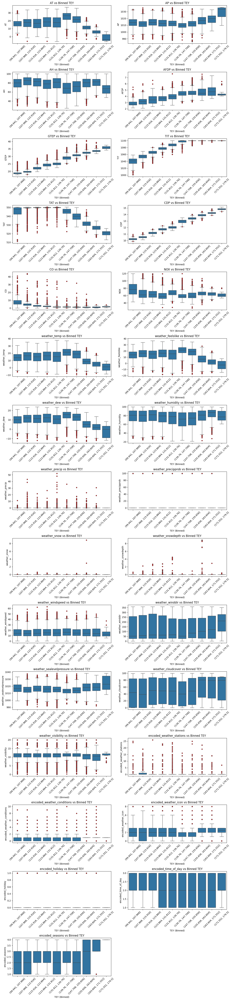

In [31]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import math

# Copy to avoid modifying original
binned_df = df_cleaned.copy()

# Select numeric columns
numeric_cols = binned_df.select_dtypes(include='number').columns.tolist()

# Remove TEY from features
numeric_cols.remove('TEY')

# Bin TEY into 10 bins
binned_df['TEY_bin'] = pd.cut(binned_df['TEY'], bins=10)

# Outlier styling
flierprops = dict(marker='o', markerfacecolor='red', markersize=4, linestyle='none')

# Subplot layout
n_features = len(numeric_cols)
n_cols = 2
n_rows = math.ceil(n_features / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(
        x='TEY_bin',
        y=col,
        data=binned_df,
        ax=axes[i],
        flierprops=flierprops
    )
    axes[i].set_title(f'{col} vs Binned TEY')
    axes[i].set_xlabel('TEY (Binned)')
    axes[i].set_ylabel(col)
    axes[i].tick_params(axis='x', rotation=45)

# Remove unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## over and under 140  kW TEY AT, AP
High R² (closer to 1) indicates strong linear correlation between predictors and the target.

t-value: indicates how strongly a predictor is associated with the target.

p-value: small (<0.05) suggests the predictor is significantly correlated with the target.

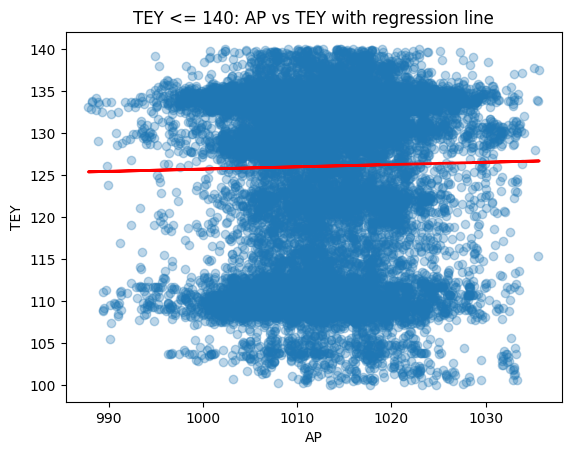

                            OLS Regression Results                            
Dep. Variable:                    TEY   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     7.292
Date:                Thu, 05 Feb 2026   Prob (F-statistic):            0.00693
Time:                        20:12:14   Log-Likelihood:                -98473.
No. Observations:               26252   AIC:                         1.970e+05
Df Residuals:                   26250   BIC:                         1.970e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         98.5974     10.166      9.699      0.0

In [32]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Subset
low = df_cleaned[df_cleaned['TEY'] <= 140]

# Regression
X = sm.add_constant(low['AP'])  # adds intercept
y = low['TEY']
model = sm.OLS(y, X).fit()

# Predicted line
pred = model.predict(X)

# Plot
plt.scatter(low['AP'], low['TEY'], alpha=0.3)
plt.plot(low['AP'], pred, color='red', linewidth=2)  # regression line
plt.xlabel('AP')
plt.ylabel('TEY')
plt.title('TEY <= 140: AP vs TEY with regression line')
plt.show()
# Check slope
print(model.summary())

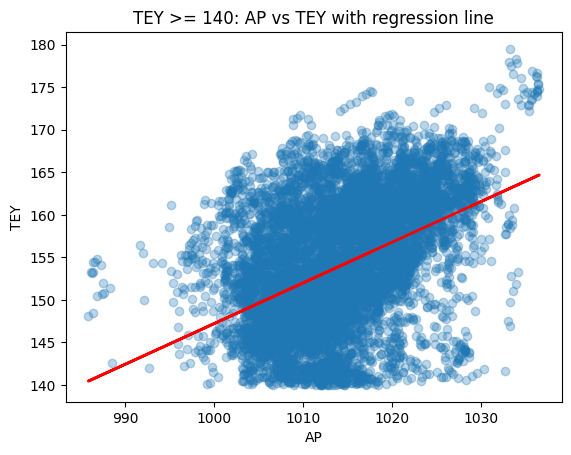

                            OLS Regression Results                            
Dep. Variable:                    TEY   R-squared:                       0.203
Model:                            OLS   Adj. R-squared:                  0.203
Method:                 Least Squares   F-statistic:                     2514.
Date:                Thu, 05 Feb 2026   Prob (F-statistic):               0.00
Time:                        20:12:14   Log-Likelihood:                -32392.
No. Observations:                9848   AIC:                         6.479e+04
Df Residuals:                    9846   BIC:                         6.480e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -330.4683      9.658    -34.216      0.0

In [33]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Subset
high_TEY = df_cleaned[df_cleaned['TEY'] >= 140]

# Regression
X = sm.add_constant(high_TEY['AP'])
y = high_TEY['TEY']
model = sm.OLS(y, X).fit()
pred = model.predict(X)

# Plot
plt.scatter(high_TEY['AP'], high_TEY['TEY'], alpha=0.3)
plt.plot(high_TEY['AP'], pred, color='red', linewidth=2)  # regression line
plt.xlabel('AP')
plt.ylabel('TEY')
plt.title('TEY >= 140: AP vs TEY with regression line')
plt.show()

# Check slope
print(model.summary())

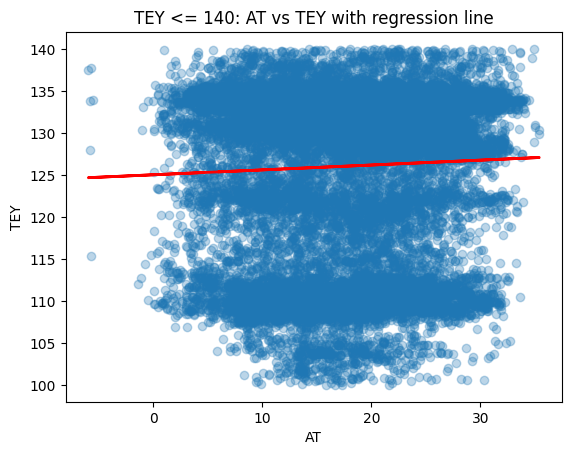

                            OLS Regression Results                            
Dep. Variable:                    TEY   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                  0.002
Method:                 Least Squares   F-statistic:                     42.36
Date:                Thu, 05 Feb 2026   Prob (F-statistic):           7.72e-11
Time:                        20:12:14   Log-Likelihood:                -98456.
No. Observations:               26252   AIC:                         1.969e+05
Df Residuals:                   26250   BIC:                         1.969e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        125.0259      0.170    737.511      0.0

In [34]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Subset
low = df_cleaned[df_cleaned['TEY'] <= 140]

# Regression
X = sm.add_constant(low['AT'])  # adds intercept
y = low['TEY']
model = sm.OLS(y, X).fit()

# Predicted line
pred = model.predict(X)

# Plot
plt.scatter(low['AT'], low['TEY'], alpha=0.3)
plt.plot(low['AT'], pred, color='red', linewidth=2)  # regression line
plt.xlabel('AT')
plt.ylabel('TEY')
plt.title('TEY <= 140: AT vs TEY with regression line')
plt.show()
# Check slope
print(model.summary())

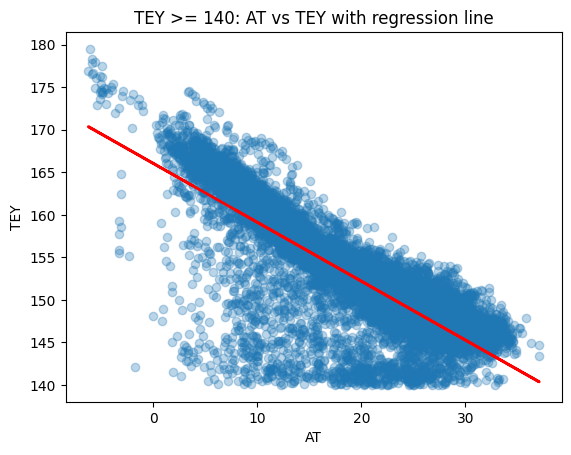

                            OLS Regression Results                            
Dep. Variable:                    TEY   R-squared:                       0.623
Model:                            OLS   Adj. R-squared:                  0.623
Method:                 Least Squares   F-statistic:                 1.628e+04
Date:                Thu, 05 Feb 2026   Prob (F-statistic):               0.00
Time:                        20:12:14   Log-Likelihood:                -28706.
No. Observations:                9848   AIC:                         5.742e+04
Df Residuals:                    9846   BIC:                         5.743e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        166.0460      0.106   1564.151      0.0

In [35]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

# Subset
high_TEY = df_cleaned[df_cleaned['TEY'] >= 140]

# Regression
X = sm.add_constant(high_TEY['AT'])
y = high_TEY['TEY']
model = sm.OLS(y, X).fit()
pred = model.predict(X)

# Plot
plt.scatter(high_TEY['AT'], high_TEY['TEY'], alpha=0.3)
plt.plot(high_TEY['AT'], pred, color='red', linewidth=2)  # regression line
plt.xlabel('AT')
plt.ylabel('TEY')
plt.title('TEY >= 140: AT vs TEY with regression line')
plt.show()

# Check slope
print(model.summary())



# Physical turbine behavior: Gas turbines need sufficient inlet temperature, pressure, and air flow to reach high energy yields.

# Below a threshold (140kW), these factors may not limit output, so no clear correlation exists.

This is consistent with operating data: in many plants, output must go above a certain threshold (~120–140 MW) before turbine inlet and exhaust conditions strongly affect power output.

"Combined cycle power plants and gas turbines are known to exhibit rapid performance degradation when load is reduced, meaning they operate less efficiently and their output becomes less sensitive to changes in operating conditions (such as temperature and pressure) at lower loads. At part‑load conditions, both gas turbine and combined cycle efficiency fall off significantly compared to design or higher load conditions."
https://doi.org/10.1115/1.2814120 


## Possible adaptive model
Stage 1 (“quick model”): Use a fast classifier or regressor on the input features to predict whether the upcoming TEY is likely to be above 140 kW. This doesn’t need to be extremely accurate, just good enough to separate “low” vs “high” TEY regimes.

Stage 2 (“accurate model”): Use a more detailed model (Random Forest, Gradient Boosting, or whatever you choose) trained only on high-TEY data to predict the exact TEY value. Optionally, a separate model could handle low-TEY predictions if needed.

In [36]:
# Pairplot numeric columns
import seaborn as sns
import matplotlib.pyplot as plt

# Select numeric columns only
numeric_cols = df_cleaned.select_dtypes(include='number').columns

# Pairplot (sampling first 1000 rows for speed)
sns.pairplot(df_cleaned[numeric_cols].sample(1000, random_state=1))
plt.show()

# Correlation matrix (numeric cols)

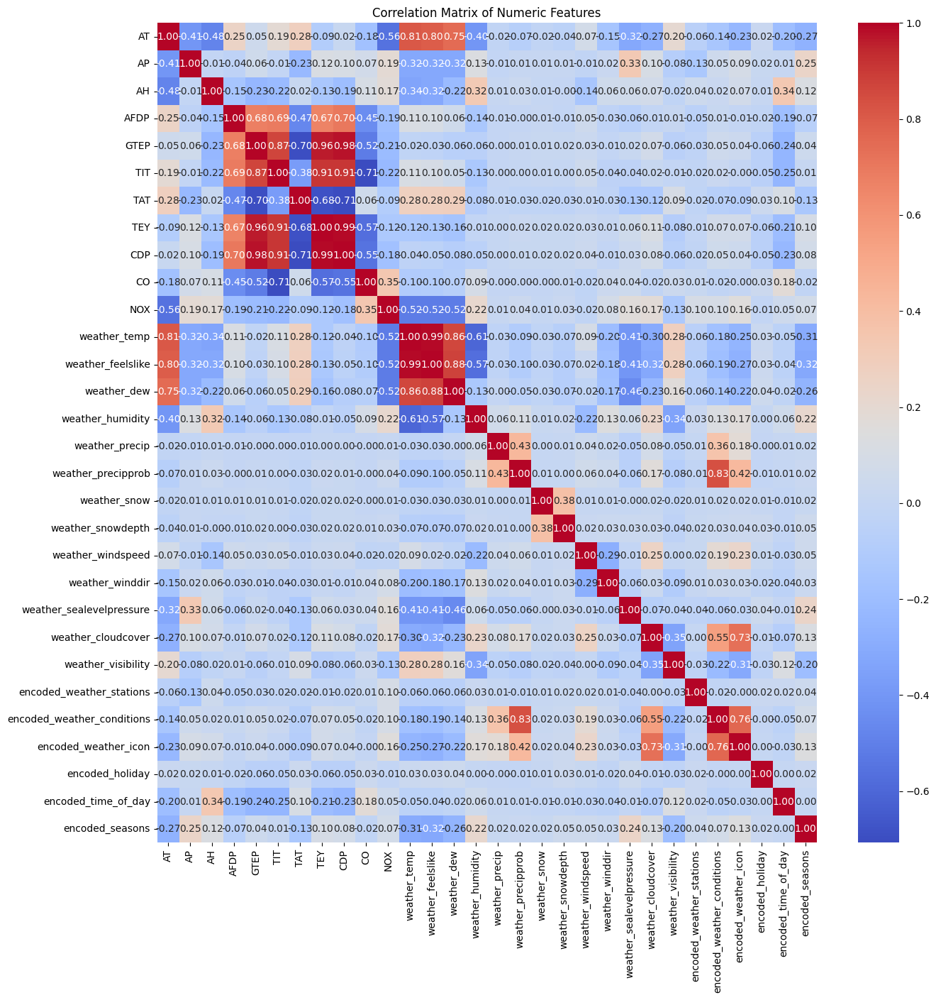

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select numeric columns only
numeric_cols = df_cleaned.select_dtypes(include='number')

# Compute correlation matrix
corr_matrix = numeric_cols.corr()

# Plot heatmap
plt.figure(figsize=(15,15))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix of Numeric Features")
plt.show()

## >0.5 (abs) → strong correlation
## 0.3–0.5 (abs) → moderate correlation
## 0.1–0.3 (abs) → small/weak correlation

In [38]:
# Select numeric columns
numeric_cols = df_cleaned.select_dtypes(include='number')

# Compute correlation matrix
corr_matrix = numeric_cols.corr()  # keep sign

top_num = 15

# Function to get top correlations by absolute value for a specific target
def top_abs_corr_for(target_col, top_n=top_num):
    # Drop self-correlation
    corr_series = corr_matrix[target_col].drop(target_col)
    
    # Take absolute value and sort
    top_abs = corr_series.abs().sort_values(ascending=False).head(top_n)
    
    # Keep original sign
    top_abs_signed = corr_series[top_abs.index]
    
    return top_abs_signed

# TEY correlations
tey_top = top_abs_corr_for('TEY')
print(f"TEY - Top {top_num} Correlations (Absolute Value):\n",tey_top,"\n")

# CO correlations
co_top = top_abs_corr_for('CO')
print(f"CO - Top {top_num} Correlations (Absolute Value):\n",co_top,"\n")

# NOX correlations
nox_top = top_abs_corr_for('NOX')
print(f"NOX - Top {top_num} Correlations (Absolute Value):\n",nox_top,"\n")

TEY - Top 15 Correlations (Absolute Value):
 CDP                    0.988788
GTEP                   0.963911
TIT                    0.909592
TAT                   -0.683146
AFDP                   0.665698
CO                    -0.567988
encoded_time_of_day   -0.205579
weather_dew           -0.157228
AH                    -0.134953
weather_feelslike     -0.130268
NOX                   -0.124349
weather_temp          -0.123990
AP                     0.117423
weather_cloudcover     0.107544
encoded_seasons        0.095598
Name: TEY, dtype: float64 

CO - Top 15 Correlations (Absolute Value):
 TIT                   -0.705657
TEY                   -0.567988
CDP                   -0.549064
GTEP                  -0.516696
AFDP                  -0.447067
NOX                    0.345491
encoded_time_of_day    0.179500
AT                    -0.176220
AH                     0.105380
weather_temp          -0.102980
weather_feelslike     -0.097025
weather_humidity       0.092417
weather_dew        

# VIF (numeric columns) - if performing linear regression
VIF (Variance Inflation Factor) is significantly less important for tree-based models 

like Random Forest and XGBoost than it is for Linear Regression.


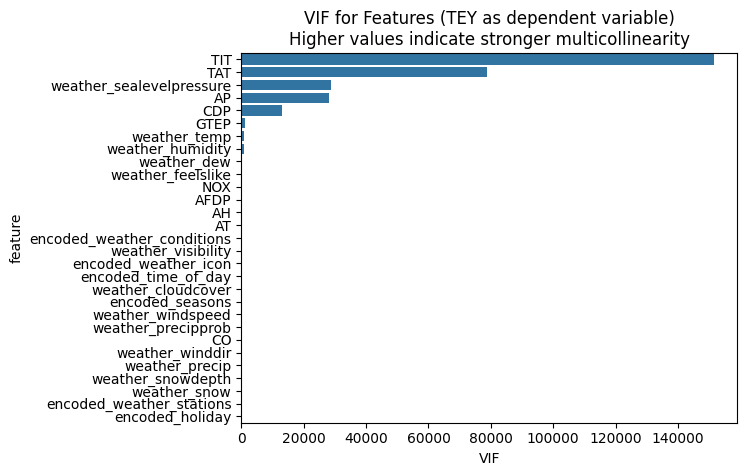

In [40]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Select numeric columns
numeric_cols = df_cleaned.select_dtypes(include='number').columns.tolist()

# Exclude dependent variable TEY
X = df_cleaned[numeric_cols].drop(columns=['TEY'])

# Fill NaNs with column mean (required for VIF calculation)
X_filled = X.fillna(X.mean())

# Compute VIF
vif_data = pd.DataFrame()
vif_data['feature'] = X_filled.columns
vif_data['VIF'] = [variance_inflation_factor(X_filled.values, i) for i in range(X_filled.shape[1])]

# Plot VIF
sns.barplot(x='VIF', y='feature', data=vif_data.sort_values('VIF', ascending=False))
plt.title("VIF for Features (TEY as dependent variable)\nHigher values indicate stronger multicollinearity", fontsize=12)
plt.show()


# Time series analysis of TEY values
Clear trends (up/down) → time matters

Seasonality (repeating patterns) → time matters

Sudden jumps → may need time-aware split

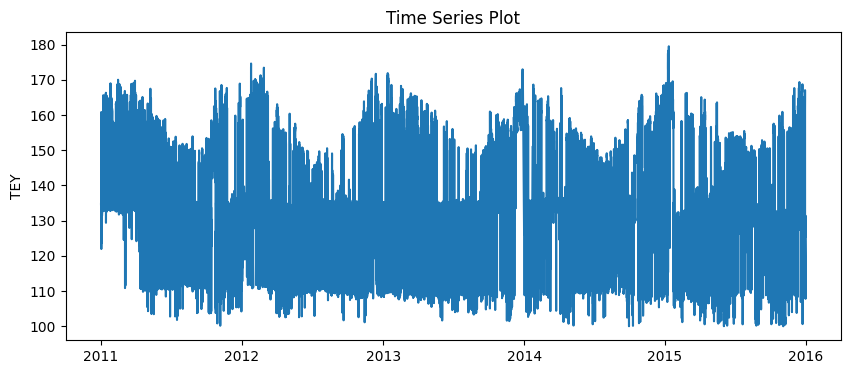

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))
plt.plot(df_cleaned['DT'], df_cleaned['TEY']) 
plt.ylabel('TEY')
plt.title('Time Series Plot')
plt.show()

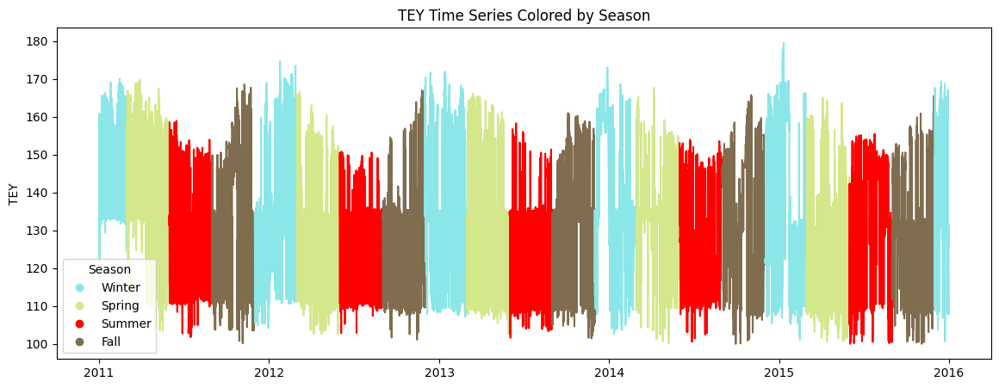

Fall 2011: high=168.52, low=100.17, mean=132.80
Fall 2012: high=166.94, low=101.15, mean=130.34
Fall 2013: high=160.97, low=101.48, mean=134.09
Fall 2014: high=165.73, low=100.03, mean=130.69
Fall 2015: high=165.53, low=100.02, mean=129.22

Winter 2011: high=170.00, low=104.23, mean=140.00
Winter 2012: high=174.61, low=107.92, mean=143.06
Winter 2013: high=172.96, low=107.20, mean=140.69
Winter 2014: high=168.63, low=102.67, mean=134.57
Winter 2015: high=179.50, low=100.64, mean=139.85

Spring 2011: high=169.72, low=103.45, mean=141.10
Spring 2012: high=166.62, low=102.56, mean=131.35
Spring 2013: high=166.10, low=102.55, mean=130.90
Spring 2014: high=167.64, low=100.22, mean=136.66
Spring 2015: high=165.06, low=100.58, mean=128.78

Summer 2011: high=158.87, low=101.81, mean=131.01
Summer 2012: high=150.78, low=102.83, mean=129.43
Summer 2013: high=158.25, low=101.66, mean=127.56
Summer 2014: high=153.93, low=100.59, mean=130.46
Summer 2015: high=155.46, low=100.04, mean=139.51



In [42]:
import matplotlib.pyplot as plt
import pandas as pd

# Ensure DT is datetime
df_cleaned['DT'] = pd.to_datetime(df_cleaned['DT'])

# Extract year
df_cleaned['year'] = df_cleaned['DT'].dt.year

# Map months to seasons
def get_season(date):
    m = date.month
    if m in [12, 1, 2]:
        return 'Winter'
    elif m in [3, 4, 5]:
        return 'Spring'
    elif m in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'

df_cleaned['season'] = df_cleaned['DT'].apply(get_season)

# Map colors
season_colors = {'Winter': '#8BE6E8', 'Spring': '#D4E88B', 'Summer': 'red', 'Fall': '#806C4F'}

dates = df_cleaned['DT']
tey = df_cleaned['TEY']
seasons = df_cleaned['season']

plt.figure(figsize=(14,5))

# Plot line segment by segment where the season is the same
start_idx = 0
for i in range(1, len(dates)):
    if seasons.iloc[i] != seasons.iloc[start_idx]:
        plt.plot(dates.iloc[start_idx:i+1], tey.iloc[start_idx:i+1], 
                 color=season_colors[seasons.iloc[start_idx]])
        start_idx = i
plt.plot(dates.iloc[start_idx:], tey.iloc[start_idx:], color=season_colors[seasons.iloc[start_idx]])

# Add legend manually
for season, color in season_colors.items():
    plt.plot([], [], color=color, marker='o', linestyle='', label=season)
plt.legend(title="Season")

plt.ylabel('TEY')
plt.title('TEY Time Series Colored by Season')
plt.show()

# --- Print high, low, mean per season per year in ordered format ---
summary = df_cleaned.copy()
summary['TEY'] = df_cleaned['TEY']

# Define season order
season_order = ['Fall', 'Winter', 'Spring', 'Summer']

# Loop through seasons first, then years
for season in season_order:
    season_data = summary[summary['season'] == season]
    for year in sorted(season_data['year'].unique()):
        group = season_data[season_data['year'] == year]
        if not group.empty:
            high = group['TEY'].max()
            low = group['TEY'].min()
            mean = group['TEY'].mean()
            print(f"{season} {year}: high={high:.2f}, low={low:.2f}, mean={mean:.2f}")
    print() 

# Highest high values are acheived in Winter, lowest high values in summer

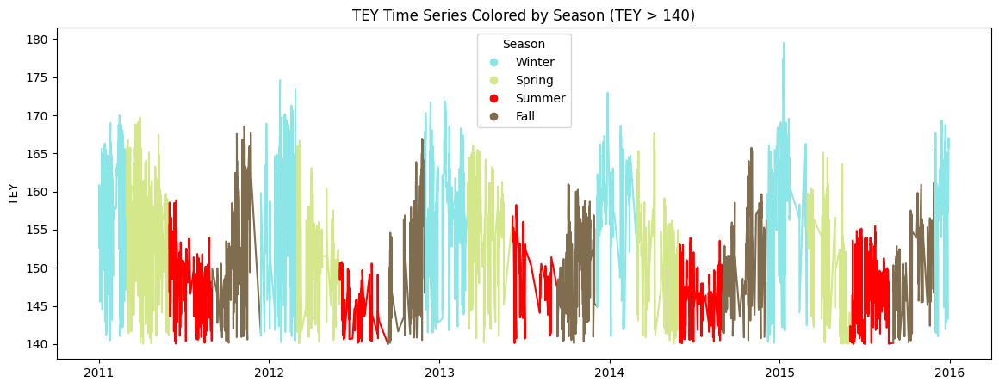

Fall 2011: high=168.52, low=140.15, mean=155.10
Fall 2012: high=166.94, low=140.03, mean=154.97
Fall 2013: high=160.97, low=140.10, mean=152.03
Fall 2014: high=165.73, low=140.50, mean=150.56
Fall 2015: high=165.53, low=140.14, mean=150.50

Winter 2011: high=170.00, low=140.46, mean=160.56
Winter 2012: high=174.61, low=140.25, mean=161.33
Winter 2013: high=172.96, low=141.78, mean=160.45
Winter 2014: high=168.63, low=140.15, mean=159.12
Winter 2015: high=179.50, low=141.00, mean=162.04

Spring 2011: high=169.72, low=140.01, mean=157.94
Spring 2012: high=166.62, low=140.07, mean=153.86
Spring 2013: high=166.10, low=140.19, mean=158.67
Spring 2014: high=167.64, low=140.01, mean=152.13
Spring 2015: high=165.06, low=140.02, mean=149.69

Summer 2011: high=158.87, low=140.04, mean=148.51
Summer 2012: high=150.78, low=140.14, mean=146.11
Summer 2013: high=158.25, low=140.11, mean=148.88
Summer 2014: high=153.93, low=140.09, mean=147.08
Summer 2015: high=155.46, low=140.01, mean=148.00

Total 

In [43]:
import matplotlib.pyplot as plt
import pandas as pd

# Ensure DT is datetime
df_cleaned['DT'] = pd.to_datetime(df_cleaned['DT'])

# Extract year
df_cleaned['year'] = df_cleaned['DT'].dt.year

# Map months to seasons
def get_season(date):
    m = date.month
    if m in [12, 1, 2]:
        return 'Winter'
    elif m in [3, 4, 5]:
        return 'Spring'
    elif m in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'

df_cleaned['season'] = df_cleaned['DT'].apply(get_season)

# Map colors
season_colors = {'Winter': '#8BE6E8', 'Spring': '#D4E88B', 'Summer': 'red', 'Fall': '#806C4F'}

# Filter for TEY > 140
df_high_TEY = df_cleaned[df_cleaned['TEY'] > 140].copy()

dates = df_high_TEY['DT']
tey = df_high_TEY['TEY']
seasons = df_high_TEY['season']

plt.figure(figsize=(14,5))

# Plot line segment by segment where the season is the same
start_idx = 0
for i in range(1, len(dates)):
    if seasons.iloc[i] != seasons.iloc[start_idx]:
        plt.plot(dates.iloc[start_idx:i+1], tey.iloc[start_idx:i+1], 
                 color=season_colors[seasons.iloc[start_idx]])
        start_idx = i
plt.plot(dates.iloc[start_idx:], tey.iloc[start_idx:], color=season_colors[seasons.iloc[start_idx]])

# Add legend manually
for season, color in season_colors.items():
    plt.plot([], [], color=color, marker='o', linestyle='', label=season)
plt.legend(title="Season")

plt.ylabel('TEY')
plt.title('TEY Time Series Colored by Season (TEY > 140)')
plt.show()

# --- Print high, low, mean per season per year for TEY > 140 ---
summary = df_high_TEY.copy()

# Define season order
season_order = ['Fall', 'Winter', 'Spring', 'Summer']

# Loop through seasons first, then years
for season in season_order:
    season_data = summary[summary['season'] == season]
    for year in sorted(season_data['year'].unique()):
        group = season_data[season_data['year'] == year]
        if not group.empty:
            high = group['TEY'].max()
            low = group['TEY'].min()
            mean = group['TEY'].mean()
            print(f"{season} {year}: high={high:.2f}, low={low:.2f}, mean={mean:.2f}")
    print()
print(f'Total high TEY values: {df_high_TEY.shape[0]}')

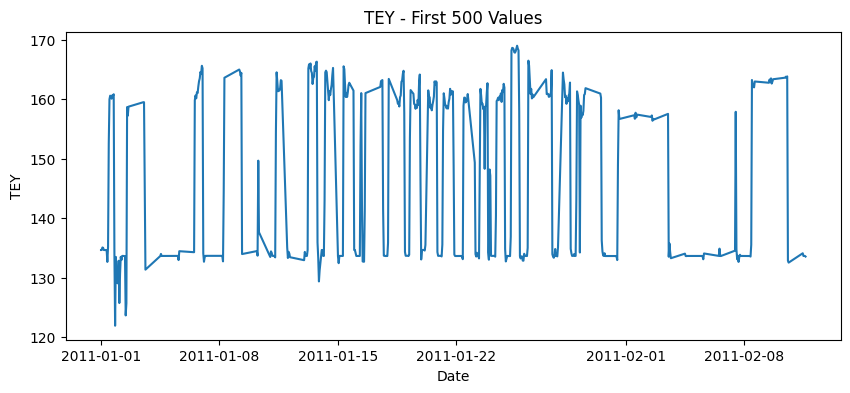

In [44]:
import matplotlib.pyplot as plt
num_slice = 500
# Slice rows
dt_slice = df_cleaned['DT'].iloc[:num_slice]
tey_slice = df_cleaned['TEY'].iloc[:num_slice]

plt.figure(figsize=(10,4))
plt.plot(dt_slice, tey_slice)
plt.xlabel('Date')
plt.ylabel('TEY')
plt.title(f'TEY - First {num_slice} Values')
plt.show()

# QQ Plot for Y = KEY

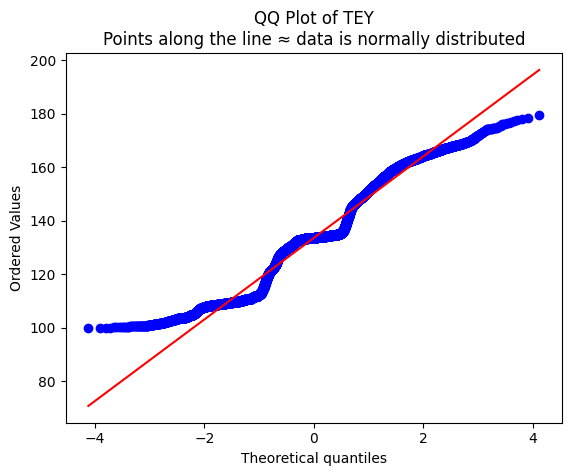

In [45]:
import scipy.stats as stats
import matplotlib.pyplot as plt

# Drop NaNs just in case
tey = df_cleaned['TEY'].dropna()

stats.probplot(tey, dist="norm", plot=plt)
plt.title("QQ Plot of TEY\nPoints along the line ≈ data is normally distributed", fontsize=12)
plt.show()

# SHAP values - numerical only

In [ ]:
import pandas as pd
import shap
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import numpy as np

# Prepare features and target
# Drop DT, holiday string columns, and dependent variable TEY from X
X = df_cleaned.drop(columns=['DT', 'TEY'] + 
                            [col for col in df_cleaned.columns if col.startswith('holiday_') and df_cleaned[col].dtype == object], 
                            errors='ignore')

# Keep only numeric columns
X = X.select_dtypes(include='number')

# # Impute missing values with column mean
# X_filled = X.fillna(X.mean())

y = df_cleaned['TEY']

#  Split into train/test
X_train, X_test, y_train, y_test = train_test_split(X_filled, y, test_size=0.2, random_state=42)

#  Train a RandomForest model (100 trees)
model = RandomForestRegressor(n_estimators=100, random_state=42)
print("SHAP Training started...")
model.fit(X_train, y_train)
print("SHAP Training complete.")

# Explain with SHAP with progress bar
explainer = shap.TreeExplainer(model)

shap_values = []
for i in tqdm(range(X_test.shape[0]), desc="Calculating SHAP"):
    sv = explainer.shap_values(X_test.iloc[i:i+1])
    shap_values.append(sv[0])

shap_values = np.vstack(shap_values)

# Summary plot
shap.summary_plot(shap_values, X_test)

CDP = Compressor discharge pressure
<br>"Higher compressor pressure ratio increases gas turbine power output and overall cycle efficiency.
Studies show that increasing the pressure ratio — which is directly related to compressor discharge pressure — lowers exergy destruction and raises power output in combined cycle power plants, because higher pressure enables more effective combustion and energy conversion."

https://doi.org/10.1016/j.csite.2022.102506

### WIP
- bulk preprocessing ????????
- more clear histograms / splitting pairplot

- confirm merged holiday date range is not 2030
- see tracker, eda useful file, and Asana notes

- scaling (for numeric)
- outlier removal
- add event time - is there as ingestion_ts